<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex02_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 02: Regression to the mean (Galton's heights)

In 1886 Francis Galton compared the heights of 1,078 fathers and their adult sons and noticed that sons of tall fathers tend to be shorter than their fathers, and sons of short fathers taller. He called the phenomenon *regression towards mediocrity*; the name stuck to the whole method (Lecture 1, history). The data are the `fsdata.csv` file from Exercise 01 (heights in inches).

Model of Lecture 1: $Y_i = \beta_0 + \beta_1 x_i + e_i$ with $x_i$ the father's height and $Y_i$ the son's height, independent errors $e_i \sim (0, \sigma^2)$. Tools of Lecture 2 (slides pp. 14–32 of the lecture PDF): standard errors $\widehat{\sigma}(\widehat{\beta}_j) = s_n \sqrt{\delta_j}$, **confidence intervals** (Czech: intervaly spolehlivosti) $\widehat{\beta}_j \pm t_{1-\alpha/2}(n-2)\,\widehat{\sigma}(\widehat{\beta}_j)$ and the **tests** (testy hypotéz) with statistics $T_j = (\widehat{\beta}_j - b)/\widehat{\sigma}(\widehat{\beta}_j)$ compared with $t_{1-\alpha/2}(n-2)$.

## Submission
Work through the tasks in this notebook (code plus short written answers in markdown cells; Python or R, as you prefer). Submit through GitHub **before the next exercise**: fork `francji1/01RAD`, save the notebook into the `HW/` folder as `01RAD_Ex02_HW_<Surname>.ipynb`, with your surname in place of `<Surname>` and without the brackets, for example `01RAD_Ex02_HW_Novak.ipynb` (team: surnames joined by an underscore), and open a pull request to `main`. The pull request should add your one file only; do not modify or delete other files. A selected student solution, and a reference solution if needed, will be published in `HW/` a week later.

Useful calls: `stats.t.ppf(1 - alpha/2, df)` for the $t$ quantile, `stats.t.sf(abs(T), df)` and `stats.t.cdf(T, df)` for tail probabilities, `model.conf_int(alpha)`, `model.t_test('father = 1')`, `model.predict(pd.DataFrame({'father': [...]}))`, `np.corrcoef`, `df.sample(n, random_state=...)`.

## Data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid', palette='deep')

local_name = "../data/fsdata.csv"
url_fsdata = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/fsdata.csv'
#fsdata = pd.read_csv(url_fsdata, index_col=0)
fsdata = pd.read_csv(local_name, index_col=0)
print(f'Rows: {fsdata.shape[0]}, columns: {fsdata.shape[1]}')
fsdata.describe().T

Rows: 1078, columns: 2


,count,mean,std,min,25%,50%,75%,max
father,1078.0,67.687097,2.744868,59.00800,65.787735,67.76660,69.60298,75.43393
son,1078.0,68.684070,2.814702,58.50708,66.931232,68.61582,70.46597,78.36479


## Task 01 - Fit and recap
Fit the regression of `son` on `father`. Compute $\widehat{\beta}_0$, $\widehat{\beta}_1$, $s_n$ and both standard errors by hand (formulas of Lectures 1 and 2) and check them against `statsmodels` (R: `summary(lm(son ~ father))`). Interpret $\widehat{\beta}_1$ in one sentence.

In [5]:
fsdata.isna().sum()

father    0
son       0
dtype: int64

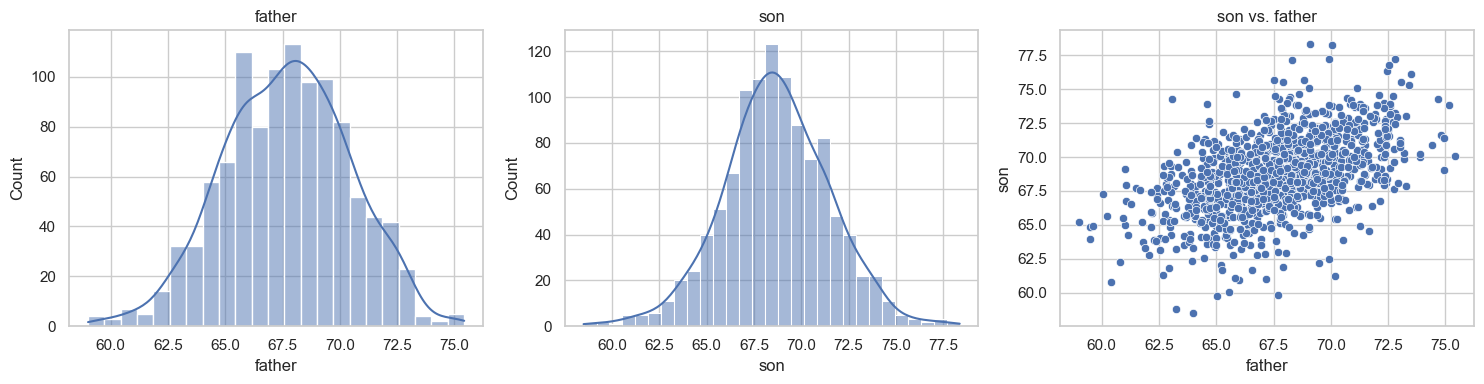

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(fsdata['father'], kde=True, ax=axes[0])
axes[0].set_title('father')

sns.histplot(fsdata['son'], kde=True, ax=axes[1])
axes[1].set_title('son')

sns.scatterplot(x='father', y='son', data=fsdata, ax=axes[2])
axes[2].set_title('son vs. father')

plt.tight_layout()
plt.show()

In [52]:
X = fsdata['father'].to_numpy()   
Y = fsdata['son'].to_numpy()  
n = len(X)

x_mean = X.mean()
y_mean = Y.mean()

# w/ intercept
beta1_hat = (np.sum(X * Y) - n * x_mean * y_mean) / (np.sum(X ** 2) - n * x_mean ** 2)
beta0_hat = y_mean - beta1_hat * x_mean

# statsmodels
model = smf.ols('son ~ father', data=fsdata).fit()

pd.DataFrame({'by hand': {'beta1_hat': f"{beta1_hat:.4f}", 'beta0_hat': f"{beta0_hat:.4f}"},
              'statsmodels': {'beta1_hat': f"{model.params[1]:.4f}", 'beta0_hat': f"{model.params[0]:.4f}"}})

/var/folders/q1/_g68zg2n2j193n5ttv1d2kmc0000gn/T/ipykernel_11404/3931070234.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'statsmodels': {'beta1_hat': f"{model.params[1]:.4f}", 'beta0_hat': f"{model.params[0]:.4f}"}})


,by hand,statsmodels
beta1_hat,0.5141,0.5141
beta0_hat,33.8866,33.8866


pokud je otec o 1 palec vyšší, je jeho syn v průměru vyšší o 0.51 palce

In [53]:
y_hat = beta0_hat + beta1_hat * X
e_hat = Y - y_hat
SSE = np.sum(e_hat ** 2)
s_n2 = SSE / (n - 2)

S_xx = np.sum((X - x_mean) ** 2)
delta_0 = 1 / n + x_mean ** 2 / S_xx
delta_1 = 1 / S_xx

var_beta0_hat = s_n2 * delta_0
var_beta1_hat = s_n2 * delta_1
se_beta0_hat = np.sqrt(var_beta0_hat)
se_beta1_hat = np.sqrt(var_beta1_hat)

pd.DataFrame({'by hand': {'s_n2': f"{s_n2:.6f}", 'SE(beta0_hat)': f"{se_beta0_hat:.6f}", 'SE(beta1_hat)': f"{se_beta1_hat:.6f}"},
              'statsmodels': {'s_n2': f"{model.scale:.6f}", 'SE(beta0_hat)': f"{model.bse[0]:.6f}", 'SE(beta1_hat)': f"{model.bse[1]:.6f}"}})

/var/folders/q1/_g68zg2n2j193n5ttv1d2kmc0000gn/T/ipykernel_11404/1518934591.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'statsmodels': {'s_n2': f"{model.scale:.6f}", 'SE(beta0_hat)': f"{model.bse[0]:.6f}", 'SE(beta1_hat)': f"{model.bse[1]:.6f}"}})


,by hand,statsmodels
s_n2,5.936804,5.936804
SE(beta0_hat),1.832354,1.832354
SE(beta1_hat),0.027049,0.027049


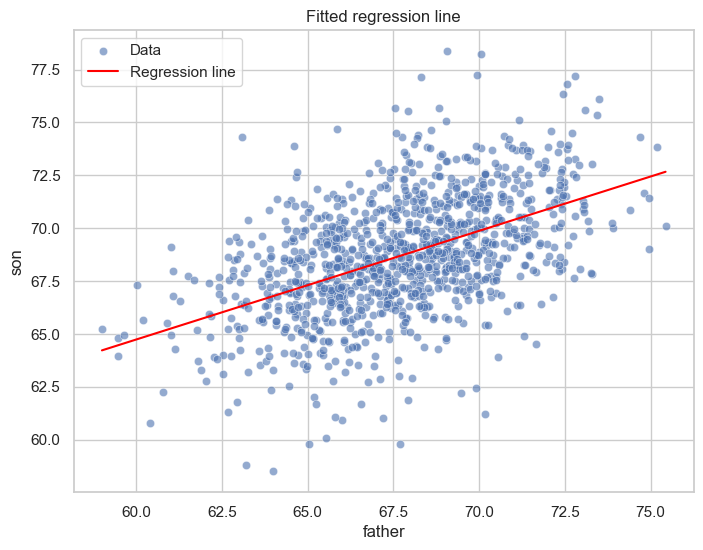

In [54]:
# your solution
x_line = np.linspace(X.min(), X.max(), 100)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X, y=Y, alpha=0.6, label='Data')
plt.plot(x_line, beta0_hat + beta1_hat * x_line, color='red', label='Regression line')

plt.xlabel('father')
plt.ylabel('son')
plt.title('Fitted regression line')
plt.legend()
plt.show()

## Task 02 - Confidence intervals
Compute the 95 % and the 99 % confidence intervals for $\beta_0$ and $\beta_1$ by hand, using the $t$ quantile, and compare with `conf_int` (R: `confint`). Why is the 99 % interval wider? Compare the widths of the intervals for $\beta_0$ and $\beta_1$ in absolute terms and relative to the estimates: which parameter is estimated more precisely? Relate your answer to the remark in Lecture 2.

In [30]:
beta_hat = np.array([beta0_hat, beta1_hat])
se_hat = np.array([se_beta0_hat, se_beta1_hat])

rows = []
for level in [0.95, 0.99]:
    alpha = 1 - level
    t_q = stats.t.ppf(1 - alpha / 2, df=n - 2)
    lower = beta_hat - t_q * se_hat
    upper = beta_hat + t_q * se_hat
    width = upper - lower
    for name, b, lo, up, w in zip(["beta0", "beta1"], beta_hat, lower, upper, width):
        rows.append({"level": level, "param": name, "t_q": t_q,
                     "estimate": b, "lower": lo, "upper": up,
                     "width": w, "rel_width": w / abs(b)})
ci_table = pd.DataFrame(rows)
ci_table


,level,param,t_q,estimate,lower,upper,width,rel_width
0,0.95,beta0,1.962171,33.886604,30.291213,37.481996,7.190784,0.212201
1,0.95,beta1,1.962171,0.514093,0.461019,0.567167,0.106148,0.206477
2,0.99,beta0,2.580406,33.886604,29.158387,38.614822,9.456434,0.279061
3,0.99,beta1,2.580406,0.514093,0.444296,0.583890,0.139593,0.271533


In [29]:
# statsmodels
conf_int95 = model.conf_int(alpha=0.05)
conf_int99 = model.conf_int(alpha=0.01)
print("95% confidence intervals:\n", conf_int95)
print("\n99% confidence intervals:\n", conf_int99)

95% confidence intervals:
                    0          1
Intercept  30.291213  37.481996
father      0.461019   0.567167

99% confidence intervals:
                    0          1
Intercept  29.158387  38.614822
father      0.444296   0.583890


99% interval je širší, protože pro vyšší spolehlivost se použije větší kvantil: $t_{0.995}(1076) \approx 2.58$ místo $t_{0.975}(1076) \approx 1.96$.

V absolutních hodnotách je 95% interval pro $\beta_0$ široký 7.19 palce a pro $\beta_1$ jen 0.106 - $\beta_1$ je odhadnut přesněji. 

Relativně k velikosti odhadu jsou šířky skoro stejné (u obou asi 21 %). Relativní šířka je totiž $2t/|T_j|$ a obě t-statistiky jsou podobné (18.5 a 19.0).

Velká nejistota úseku plyne z $\delta_0 = 1/n + \overline{x}^2/S_{xx}$. Data leží v rozmezí 59–75 palců, daleko od $x = 0$, takže $\widehat{\beta}_0$ je extrapolace a nejistota sklonu se do něj přenáší vynásobená $\overline{x}$: $\widehat{\sigma}(\widehat{\beta}_0) \approx \overline{x}\,\widehat{\sigma}(\widehat{\beta}_1) = 67.7 \cdot 0.027 \approx 1.83$.


## Task 03 - Is the father's height informative?
Test $H_0: \beta_1 = 0$ against $H_1: \beta_1 \neq 0$ at $\alpha = 0.05$: report $T_1$, the critical value $t_{0.975}(n-2)$, the $p$-value and the decision. What does the rejection say about the relationship, and what does it *not* say (think of the lecture's warning about linearity)?

In [32]:
alpha = 0.05
T1 = beta1_hat / se_beta1_hat
t_crit = stats.t.ppf(1 - alpha / 2, df=n - 2)
p_value = 2 * stats.t.sf(abs(T1), df=n - 2)

print(f"T1 = {T1:.4f}")
print(f"t_0.975({n-2}) = {t_crit:.4f}")
print(f"p-value = {p_value:.4g}")

T1 = 19.0062
t_0.975(1076) = 1.9622
p-value = 1.121e-69


## Task 04 - Regression to the mean
If sons were on average exactly as tall as their fathers plus a constant, the slope would be $\beta_1 = 1$. Test $H_0: \beta_1 = 1$ against $H_1: \beta_1 \neq 1$ (the test with a given candidate value $b_1$ from Lecture 2) and also against the **one-sided alternative** (jednostranná alternativa) $H_1: \beta_1 < 1$: the lecture treats two-sided alternatives, for the one-sided one use the same statistic $T = (\widehat{\beta}_1 - 1)/\widehat{\sigma}(\widehat{\beta}_1)$, reject when $T < -t_{1-\alpha}(n-2)$, and the $p$-value is $P(t(n-2) < T)$. Check the duality of the two-sided test with the 95 % confidence interval from Task 02. Explain in your own words why Galton spoke of *regression* (regrese k průměru) and what the estimated slope says about sons of very tall and very short fathers.

In [ ]:
alpha = 0.05
b1 = 1
T = (beta1_hat - b1) / se_beta1_hat

# oboustranná alternativa H1: beta1 != 1
t_crit_2 = stats.t.ppf(1 - alpha / 2, df=n - 2)
p_2 = 2 * stats.t.sf(abs(T), df=n - 2)

# jednostranná alternativa H1: beta1 < 1
t_crit_1 = stats.t.ppf(1 - alpha, df=n - 2)
p_1 = stats.t.cdf(T, df=n - 2)          # P(t(n-2) < T)

print(f"T = {T:.4f}")
print(f"Oboustranný: p = {p_2:.4g}")
print(f"Jednostranný: p = {p_1:.4g}")

T = -17.9641
Oboustranný: p = 2.61e-63 
Jednostranný: p = 1.305e-63


## Task 05 - The intercept
Test $H_0: \beta_0 = 0$. Then write $\widehat{\beta}_0 = \overline{y} - \widehat{\beta}_1 \overline{x}$, plug in the sample means and explain why the intercept is far from zero even though sons are on average only about one inch taller than their fathers. Would a model through the origin make sense here?

In [ ]:
T0 = beta0_hat / se_beta0_hat
t_crit = stats.t.ppf(0.975, df=n - 2)
p0 = 2 * stats.t.sf(abs(T0), df=n - 2)

print(f"T0 = {T0:.4f}, t_crit = {t_crit:.4f}, p = {p0:.4g}")

print(f"y_mean - x_mean = {y_mean - x_mean:.4f}")
print(f"beta0_hat = {y_mean:.4f} - {beta1_hat:.4f} * {x_mean:.4f} = {y_mean:.4f} - {beta1_hat * x_mean:.4f} = {y_mean - beta1_hat * x_mean:.4f}")


T0 = 18.4935, t_crit = 1.9622, p = 1.604e-66
y_mean = 68.6841, x_mean = 67.6871, y_mean - x_mean = 0.9970
beta0_hat = 68.6841 - 0.5141 * 67.6871 = 68.6841 - 34.7975 = 33.8866


## Task 06 - Point predictions
Predict the mean height of sons whose fathers are 60, 64, 68, 72 and 76 inches tall and tabulate the difference *predicted son minus father*. For which father's height do the two coincide? (Confidence and prediction intervals for these predictions come in Lecture 4; here point predictions are enough.)

In [44]:
x_new = np.array([60, 64, 68, 72, 76])
y_pred = beta0_hat + beta1_hat * x_new

pred_table = pd.DataFrame({
    "father": x_new,
    "predicted_son": y_pred,
    "son_minus_father": y_pred - x_new,
})
print(pred_table.round(2))

# kde se predikce rovná výšce otce
x_star = beta0_hat / (1 - beta1_hat)
print(f"x* = {x_star:.2f}")
print(f"predicted son height at x* = {beta0_hat + beta1_hat * x_star:.2f}")

   father  predicted_son  son_minus_father
0      60          64.73              4.73
1      64          66.79              2.79
2      68          68.84              0.84
3      72          70.90             -1.10
4      76          72.96             -3.04
x* = 69.74
predicted son height at x* = 69.74


## Task 07 - Reverse regression
Fit the reverse regression of `father` on `son` and report its slope. Verify numerically that the product of the two slopes equals the square of the sample correlation coefficient $r$ of the two heights (`np.corrcoef`), and explain why both slopes are smaller than 1. Is regression to the mean a causal effect of fathers on sons, or a statistical property of the two distributions?

In [62]:
y_mean = np.mean(Y)
S_yy = np.sum((Y - y_mean) ** 2)
S_xy = np.sum((X - x_mean) * (Y - y_mean))

gamma1_hat = S_xy / S_yy

r = np.corrcoef(X, Y)[0, 1]

print(f"beta1_hat  (son ~ father) = {beta1_hat:.4f}")
print(f"gamma1_hat (father ~ son) = {gamma1_hat:.4f}")
print(f"beta*gamma = {beta1_hat * gamma1_hat:.6f}")
print(f"r^2 = {r**2:.6f}")
print(f"s_x = {np.std(X, ddof=1):.3f}, s_y = {np.std(Y, ddof=1):.3f}")

beta1_hat  (son ~ father) = 0.5141
gamma1_hat (father ~ son) = 0.4889
beta*gamma = 0.251340
r^2 = 0.251340
s_x = 2.745, s_y = 2.815


## Task 08 - Sample size and precision
Draw random subsamples of 30, 100 and 300 father-son pairs (fix the random seed), fit the model in each and compare the widths of the 95 % intervals for $\beta_1$ with the full-sample interval. Explain the pattern through $\mathrm{Var}(\widehat{\beta}_1) = \sigma^2 / S_{xx}$. *Optional:* repeat the subsampling with $n = 100$ five hundred times, treat the full-sample $\widehat{\beta}_1$ as the true value and estimate how often the 95 % interval covers it.

In [57]:
def fit_slope_ci(x, y, level=0.95):
    model = sm.OLS(y, sm.add_constant(x)).fit()
    lower, upper = model.conf_int(alpha=1 - level)[1] 
    return {
        "n": int(model.nobs),
        "beta1": model.params[1],
        "se": model.bse[1],
        "lower": lower,
        "upper": upper,
        "width": upper - lower,
    }

In [59]:
rng = np.random.default_rng(42)  # fixed seed for reproducibility

results = []
for m in [30, 100, 300]:
    idx = rng.choice(n, size=m, replace=False)  # same indices for X and Y keeps the pairs
    results.append(fit_slope_ci(X[idx], Y[idx]))
results.append(fit_slope_ci(X, Y))  # full sample

size_table = pd.DataFrame(results)
full_width = size_table["width"].iloc[-1]
size_table["width_ratio_vs_full"] = size_table["width"] / full_width
size_table["sqrt_N_over_n"] = np.sqrt(n / size_table["n"])

size_table

,n,beta1,se,lower,upper,width,width_ratio_vs_full,sqrt_N_over_n
0,30,0.440426,0.160696,0.111255,0.769597,0.658342,6.202086,5.994442
1,100,0.539022,0.102749,0.335120,0.742925,0.407805,3.841836,3.283291
2,300,0.560511,0.051955,0.458266,0.662756,0.204490,1.926453,1.895609
3,1078,0.514093,0.027049,0.461019,0.567167,0.106148,1.000000,1.000000


In [60]:
rng_sim = np.random.default_rng(123)
beta1_true = fit_slope_ci(X, Y)["beta1"]  # full-sample estimate as "truth"

n_sim, m = 500, 100
covered = np.empty(n_sim, dtype=bool)
widths = np.empty(n_sim)

for i in range(n_sim):
    idx = rng_sim.choice(n, size=m, replace=False)
    res = fit_slope_ci(X[idx], Y[idx])
    covered[i] = res["lower"] <= beta1_true <= res["upper"]
    widths[i] = res["width"]

coverage = covered.mean()
mc_se = np.sqrt(coverage * (1 - coverage) / n_sim)  # Monte Carlo standard error

print(f"Estimated coverage: {coverage:.3f} "
      f"(approx. 95% MC interval: {coverage - 1.96*mc_se:.3f} to {coverage + 1.96*mc_se:.3f})")
print(f"Mean CI width for n = {m}: {widths.mean():.4f}")

Estimated coverage: 0.974 (approx. 95% MC interval: 0.960 to 0.988)
Mean CI width for n = 100: 0.3585
